# Comparing models under consistent scoring: FZ0, Diebold-Mariano and the model confidence set in five stress windows

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 03 and 04 of this topic (the backtests that decide eligibility)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- say why VaR and ES must be scored together, and write and compute the FZ0 loss with the engine's function;
- show with a scale experiment what it means for a scoring rule to be consistent, and read the result for three models;
- compare two models with the Diebold-Mariano test, say what its sign means, and reproduce the committed comparison against the champion;
- read the model confidence set of the five committed windows, recompute it for the two that commit their returns, and say why the three others cannot be recomputed;
- state the champion rule (eligibility by the traditional backtests, then ranking by FZ0) and apply it to the five stress windows.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 arch==8.0.0 pandas==3.0.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import special, stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib", "arch", "pandas"):
    print(name, md.version(name))

# The engine's light values, in the words this notebook prints
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2
arch 8.0.0
pandas 3.0.6


## Data

Five windows of case C11 are read, one per market stress: `equity-2007-09` (the financial crisis), `equity-2020` (the pandemic crash), `rates-2022` (the hiking cycle), `fx-2008` (the euro against the dollar) and `mixed-2023` (the bank turmoil). Each holds, for 17 models and two tail levels, the VaR and ES paths, the mean FZ0 and tick loss, the eligibility verdict and a `comparison` block with the champion, the Diebold-Mariano rows against it and the model confidence set.

Only `rates-2022` and `fx-2008` commit the realised losses (their sources are `mirror-allowed`); the three others hold derived-only returns. The scores of those two windows are therefore recomputed here from the arrays, and the three others are read from the committed rows. The next cell loads the files and the helper that gathers one window's forecasts and scores.

In [2]:
# Load the five windows and define the helper that gathers one window's forecasts (return convention) for a tail level
ROOT = Path("../../..").resolve()
NAMES = ("equity-2007-09", "equity-2020", "rates-2022", "fx-2008", "mixed-2023")
docs = {w: json.loads((ROOT / "data" / "derived" / "C11" / f"{w}.json").read_text(encoding="utf-8")) for w in NAMES}
print("committed rows baked by riskvalidation", docs["fx-2008"]["provenance"]["riskvalidation_version"], "| installed", rv.__version__)


def forecasts_of(window, alpha):
    """Per model: the VaR and ES in the return convention (None for the ES of a model without one) and the committed level block."""
    out = {}
    for model in docs[window]["outputs"]["models"]:
        level = [lv for lv in model["by_level"] if lv["alpha"] == alpha][0]
        es = None if level["es_status"] != "forecast" else -np.array(level["es"])
        out[model["model_id"]] = (-np.array(level["var"]), es, level, model["eligible"])
    return out


for w in NAMES:
    out = docs[w]["outputs"]
    print(f"{w:15s} {out['window']['n_forecast_days']:4d} days | realised losses {out['grid']['realised_loss']['status']:21s} | eligible models {int(docs[w]['impact']['eligible_models']['value'])}")

committed rows baked by riskvalidation 1.0.1 | installed 1.0.1
equity-2007-09   504 days | realised losses withheld-derived-only | eligible models 0
equity-2020      104 days | realised losses withheld-derived-only | eligible models 4
rates-2022       249 days | realised losses included              | eligible models 4
fx-2008          251 days | realised losses included              | eligible models 10
mixed-2023        64 days | realised losses withheld-derived-only | eligible models 17


## Method

### Step 1: scoring VaR and ES together, the FZ0 loss

A scoring rule is **consistent** for a statistic if reporting the true statistic minimises the expected score, so a forecaster is rewarded for honesty. The VaR is elicitable: the tick (pinball) loss $(\alpha - \mathbb 1\{y < v\})(y - v)$ is consistent for it. The ES is not elicitable on its own (Gneiting, 2011), but the **pair** (VaR, ES) is (Fissler and Ziegel, 2016), so there are losses that reward a forecaster for the right VaR and the right ES at once. Patton, Ziegel and Chen (2019) pick the one whose loss differences are homogeneous of degree zero, free of tuning parameters, the FZ0 loss. In the return convention, with $y$ the realised return, $v < 0$ the VaR, $e \le v$ the ES:

$$L_{FZ0}(y, v, e; \alpha) = -\frac{1}{\alpha\,e}\,\mathbb 1\{y \le v\}\,(v - y) + \frac{v}{e} + \ln(-e) - 1$$

The loss can be negative and only **differences** between models are meaningful. The engine's `fz0_loss(y, v, e, alpha)` gives it day by day, `tick_loss` the pinball loss, and `mean_scores` the means. We write the loss by hand for one model and check the engine, then recompute the mean FZ0 and tick loss of every model with an ES in `fx-2008` and compare them with the committed rows.

In [3]:
# FZ0 by hand for ewma at 2.5% in fx-2008 against the engine, then the mean scores of every model against the committed rows
from riskvalidation.market.scoring import fz0_loss, mean_scores, tick_loss

returns = -np.array(docs["fx-2008"]["outputs"]["grid"]["realised_loss"]["loss"])
alpha = 0.025
book = forecasts_of("fx-2008", alpha)
v, e, level, eligible = book["ewma"]
by_hand = -(1.0 / (alpha * e)) * (returns <= v) * (v - returns) + v / e + np.log(-e) - 1.0
print(f"ewma: mean FZ0 by hand {by_hand.mean():.6f} | engine {fz0_loss(returns, v, e, alpha).mean():.6f} | committed {level['fz0_mean']:.6f}")
print(f"FZ0 on a day without exceedance: {by_hand[returns > v].mean():.4f} on average | on the {int((returns <= v).sum())} exceedance days: {by_hand[returns <= v].mean():.4f}")

worst = 0.0
for alpha in (0.01, 0.025):
    for model_id, (v, e, level, eligible) in forecasts_of("fx-2008", alpha).items():
        if e is None:
            scores = mean_scores(returns, v, np.full(returns.size, np.nan), alpha)
            worst = max(worst, abs(scores.tick_mean - level["tick_loss_mean"]))
        else:
            scores = mean_scores(returns, v, e, alpha)
            worst = max(worst, abs(scores.fz0_mean - level["fz0_mean"]), abs(scores.tick_mean - level["tick_loss_mean"]))
print(f"mean FZ0 and mean tick loss recomputed for all 17 models and both levels: largest difference from the committed rows {worst:.2e}")

ewma: mean FZ0 by hand -3.706963 | engine -3.706963 | committed -3.706963
FZ0 on a day without exceedance: -3.9515 on average | on the 8 exceedance days: 3.7209
mean FZ0 and mean tick loss recomputed for all 17 models and both levels: largest difference from the committed rows 4.63e-09


### Step 2: what consistency means, shown by scaling a forecast

If the score is consistent, a forecast that is too small should score worse than a better one, and the **best scaling** of a model's forecast tells how far it is from its own optimum. The cell multiplies the VaR and the ES of three models in `fx-2008` at 2.5 percent by a factor $k$ from 0.6 to 1.8 and computes the mean FZ0 of each scaled forecast. The factor at which the curve is lowest is the one the realised returns prefer: near 1 means the forecast was already the best of its scaled family; far above 1 means it was too small for what happened.

ewma    factor 1.00: mean FZ0 -3.7070 | best factor 1.05: -3.7114
evt-mf  factor 1.00: mean FZ0 -3.7162 | best factor 1.00: -3.7162
hs-250  factor 1.00: mean FZ0 -3.4294 | best factor 1.40: -3.6350


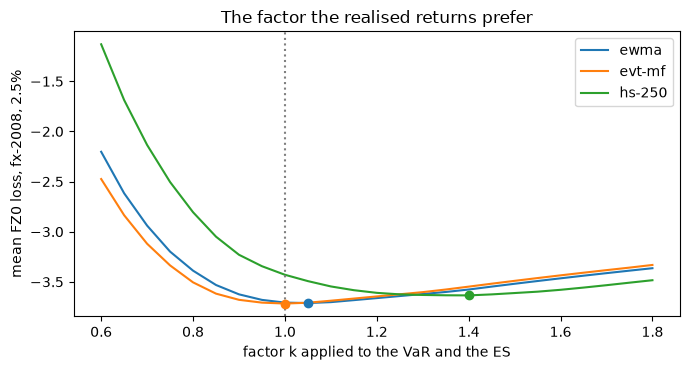

In [4]:
# Mean FZ0 of the VaR and ES of three models multiplied by a factor k, and the factor each model prefers
factors = np.linspace(0.6, 1.8, 25)
curves = {}
for model_id in ("ewma", "evt-mf", "hs-250"):
    v, e, level, eligible = book[model_id]
    curves[model_id] = np.array([fz0_loss(returns, k * v, k * e, 0.025).mean() for k in factors])
    best = int(np.argmin(curves[model_id]))
    print(f"{model_id:7s} factor 1.00: mean FZ0 {fz0_loss(returns, v, e, 0.025).mean():.4f} | best factor {factors[best]:.2f}: {curves[model_id][best]:.4f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
for model_id, curve in curves.items():
    ax.plot(factors, curve, label=model_id)
    ax.scatter(factors[int(np.argmin(curve))], curve.min(), zorder=3)
ax.axvline(1.0, color="grey", linestyle=":")
ax.set_xlabel("factor k applied to the VaR and the ES")
ax.set_ylabel("mean FZ0 loss, fx-2008, 2.5%")
ax.set_title("The factor the realised returns prefer")
ax.legend()
fig.tight_layout()
plt.show()

### Step 3: Diebold-Mariano against the champion

To say that one model is better than another, and not just lucky on this window, Diebold and Mariano (1995) test whether the mean of the loss differential $d_t = L_t^{A} - L_t^{B}$ is zero:

$$DM = \frac{\bar d}{\sqrt{\widehat{\mathrm{LRV}}/T}} \xrightarrow{d} N(0,1), \qquad \widehat{\mathrm{LRV}} = \hat\gamma_0 + 2\sum_{j=1}^{h}\left(1 - \tfrac{j}{h+1}\right)\hat\gamma_j$$

with $\hat\gamma_j$ the sample autocovariances of $d_t$ and $h$ the Bartlett lags; for one-step forecasts the committed comparison uses $h = 0$. A **negative** $\bar d$ means model A has the lower loss, so it is better. The engine's `diebold_mariano(loss_a, loss_b, lags)` returns the mean difference, the statistic and the two-sided normal p-value. The cell finds the champion by the rule of step 5, compares every other model with it on FZ0 and on tick loss, and sets the result beside the committed rows.

In [5]:
# Champion by the rule of step 5, then Diebold-Mariano of every other model against it, on FZ0 and on tick loss
from riskvalidation.market.scoring import diebold_mariano


def champion_of(window, alpha, y):
    """Lowest mean FZ0 among the eligible models with an ES on every day, and the scores of all models that have an ES."""
    scores = {m: fz0_loss(y, v, e, alpha) for m, (v, e, level, eligible) in forecasts_of(window, alpha).items() if e is not None}
    pool = [m for m in scores if forecasts_of(window, alpha)[m][3]]
    return (min(pool, key=lambda m: scores[m].mean()) if pool else None), scores


for window in ("fx-2008", "rates-2022"):
    y = -np.array(docs[window]["outputs"]["grid"]["realised_loss"]["loss"])
    for alpha in (0.01, 0.025):
        champion, fz = champion_of(window, alpha, y)
        committed_champion = {c["alpha"]: c["model_id"] for c in docs[window]["outputs"]["comparison"]["champions"]}[alpha]
        book = forecasts_of(window, alpha)
        tick = {m: tick_loss(y, v, alpha) for m, (v, e, level, eligible) in book.items()}
        rows = {(r["model_id"], r["loss"]): r for r in docs[window]["outputs"]["comparison"]["dm"] if r["alpha"] == alpha}
        worst, compared, better = 0.0, 0, 0
        for model_id in book:
            if model_id == champion:
                continue
            for kind, series in (("fz0", fz), ("tick", tick)):
                row = rows[(model_id, kind)]
                if row["direction"] == "not-evaluated" or model_id not in series:
                    continue
                result = diebold_mariano(series[model_id], series[champion], 0)
                worst = max(worst, abs(result.statistic - row["dm_statistic"]), abs(result.p_value - row["p_value"]))
                compared += 1
                better += result.p_value < 0.05 and result.mean_diff < 0
        print(f"{window:11s} alpha {alpha:5.3f} | champion {champion} (committed {committed_champion}) | DM rows compared {compared} | largest difference {worst:.1e} | "
              f"models significantly better than the champion: {better}")

fx-2008     alpha 0.010 | champion caviar-es (committed caviar-es) | DM rows compared 28 | largest difference 4.6e-09 | models significantly better than the champion: 0
fx-2008     alpha 0.025 | champion evt-mf (committed evt-mf) | DM rows compared 29 | largest difference 4.9e-09 | models significantly better than the champion: 0
rates-2022  alpha 0.010 | champion ewma (committed ewma) | DM rows compared 29 | largest difference 4.7e-09 | models significantly better than the champion: 1
rates-2022  alpha 0.025 | champion ewma (committed ewma) | DM rows compared 29 | largest difference 4.5e-09 | models significantly better than the champion: 0


### Step 4: the model confidence set

Diebold-Mariano compares two models. The model confidence set of Hansen, Lunde and Nason (2011) answers the question a validator asks about a whole ladder: which models are **not distinguishable from the best**? It starts with all models, tests the hypothesis that they have equal expected loss, and while it is rejected eliminates the worst model, using a bootstrap for the null distribution; the models that survive form the set, at confidence $1-\alpha_{MCS}$. Contraste uses the range statistic ($T_R$), 90 percent confidence, a stationary bootstrap of 1,000 draws and the FZ0 loss. A model is in the set when its MCS p-value is at least 0.10. The engine computes it with `arch.bootstrap.MCS` (the optional `market` extra, installed in this environment with `pandas`), seeded: the same losses and the same seed give the same p-values. Two windows commit their realised returns, `rates-2022` and `fx-2008`, so the notebook **recomputes** their sets at both levels from the committed forecasts, with the seed of the bake (42), and compares them with the committed p-values. For the three others the returns are withheld, the FZ0 losses cannot be formed, and the notebook **reads** the committed sets. The cell prints, for the five windows at 1 percent, the size of the set and the models outside it, and then the recomputation.

In [6]:
# The committed model confidence sets at 1% (FZ0, TR statistic, 90% confidence): size of the set and the models outside it
for window in NAMES:
    comparison = docs[window]["outputs"]["comparison"]
    mcs = [m for m in comparison["mcs"] if m["alpha"] == 0.01][0]
    outside = [(m["model_id"], round(m["p_value"], 3)) for m in mcs["members"] if not m["in_set"]]
    print(f"{window:15s} {mcs['statistic']} {mcs['confidence']:.0%} | {mcs['n_bootstrap']} draws, block {mcs['block_length']} | {mcs['n_in_set']} of {len(mcs['members'])} models in the set")
    print(f"{'':15s} outside the set (MCS p-value): {outside}")

# Recompute the sets of the two windows that commit their returns (the seed of the bake, 42) and compare them with the committed p-values
from riskvalidation.market.scoring import model_confidence_set

for window in ("rates-2022", "fx-2008"):
    returns = -np.array(docs[window]["outputs"]["grid"]["realised_loss"]["loss"])
    for alpha in (0.01, 0.025):
        committed = [m for m in docs[window]["outputs"]["comparison"]["mcs"] if m["alpha"] == alpha][0]
        ids = [m["model_id"] for m in committed["members"]]
        book = forecasts_of(window, alpha)
        losses = np.column_stack([fz0_loss(returns, book[i][0], book[i][1], alpha) for i in ids])
        fresh = model_confidence_set(losses, committed["confidence"], committed["statistic"], committed["n_bootstrap"], committed["block_length"], 42)
        gap = max(abs(fresh.p_values[k] - m["p_value"]) for k, m in enumerate(committed["members"]))
        same = [ids[k] for k in fresh.members] == [m["model_id"] for m in committed["members"] if m["in_set"]]
        print(f"{window:11s} alpha {alpha:5.3f} | recomputed set: {len(fresh.members)} of {len(ids)} models | largest difference of the MCS p-values to the committed ones: {gap:.1e} | same set: {same}")

equity-2007-09  TR 90% | 1000 draws, block 10 | 12 of 14 models in the set
                outside the set (MCS p-value): [('dn-rolling', 0.077), ('gas-fz-2', 0.078)]
equity-2020     TR 90% | 1000 draws, block 10 | 14 of 14 models in the set
                outside the set (MCS p-value): []
rates-2022      TR 90% | 1000 draws, block 10 | 14 of 14 models in the set
                outside the set (MCS p-value): []
fx-2008         TR 90% | 1000 draws, block 10 | 13 of 14 models in the set
                outside the set (MCS p-value): [('dn-rolling', 0.049)]
mixed-2023      TR 90% | 1000 draws, block 10 | 2 of 14 models in the set
                outside the set (MCS p-value): [('hs-250', 0.0), ('hs-500', 0.0), ('awhs', 0.0), ('dn-rolling', 0.0), ('ewma', 0.0), ('egarch-t', 0.0), ('fhs', 0.0), ('evt-mf', 0.0), ('caviar-es', 0.0), ('gas-fz-1', 0.0), ('gas-fz-2', 0.0), ('gas-hybrid', 0.0)]
rates-2022  alpha 0.010 | recomputed set: 14 of 14 models | largest difference of the MCS p-values to

### Step 5: the champion rule

The ladder separates two questions. **Eligibility** asks whether a model is acceptable: it must not be red on Kupiec, on conditional coverage or on the Acerbi-Szekely test at either level (notebooks 03 and 04). **Ranking** asks which acceptable model forecasts best: the lowest mean FZ0, among the eligible models that have an ES on every day. This is the comparative-backtest frame of Nolde and Ziegel (2017): a validator wants to know whether a challenger beats the champion, not only whether the champion is rejected. A window can have no champion: if no eligible model has an ES on every day there is no FZ0 score to rank, and the document says so instead of choosing one. The cell reads the committed champions and the number of eligible models in the five windows, and the mean FZ0 of the champion.

In [7]:
# Eligible models, champions and the champion's mean FZ0 in the five windows, as committed
print(f"{'window':15s} {'eligible':>8s}  {'champion 1%':14s} {'FZ0 1%':>8s}  {'champion 2.5%':14s} {'FZ0 2.5%':>9s}")
for window in NAMES:
    doc = docs[window]
    champions = {c["alpha"]: c["model_id"] for c in doc["outputs"]["comparison"]["champions"]}
    scores = {}
    for alpha, champion in champions.items():
        scores[alpha] = None if champion is None else forecasts_of(window, alpha)[champion][2]["fz0_mean"]
    cell = lambda alpha: ("none" if champions[alpha] is None else champions[alpha], "-" if scores[alpha] is None else f"{scores[alpha]:.3f}")
    print(f"{window:15s} {int(doc['impact']['eligible_models']['value']):8d}  {cell(0.01)[0]:14s} {cell(0.01)[1]:>8s}  {cell(0.025)[0]:14s} {cell(0.025)[1]:>9s}")
print("reason when there is no champion:", docs["equity-2007-09"]["outputs"]["comparison"]["champions"][0]["reason"])

window          eligible  champion 1%      FZ0 1%  champion 2.5%   FZ0 2.5%
equity-2007-09         0  none                  -  none                   -
equity-2020            4  fhs              -1.986  evt-mf            -2.364
rates-2022             4  ewma             -3.811  ewma              -4.002
fx-2008               10  caviar-es        -3.557  evt-mf            -3.716
mixed-2023            17  gjr-t            -4.439  gjr-t             -4.623
reason when there is no champion: no eligible model has an ES on every day, so none has an FZ0 score to rank


The last figure ranks the models of `fx-2008` at 1 percent by mean FZ0, from the recomputed scores. A bar is coloured by whether the model is in the confidence set, and a hatch marks the models removed by the eligibility gates. The champion is the lowest bar among the eligible ones with an ES; a model with a lower bar that is not eligible is not a champion, whatever its score.

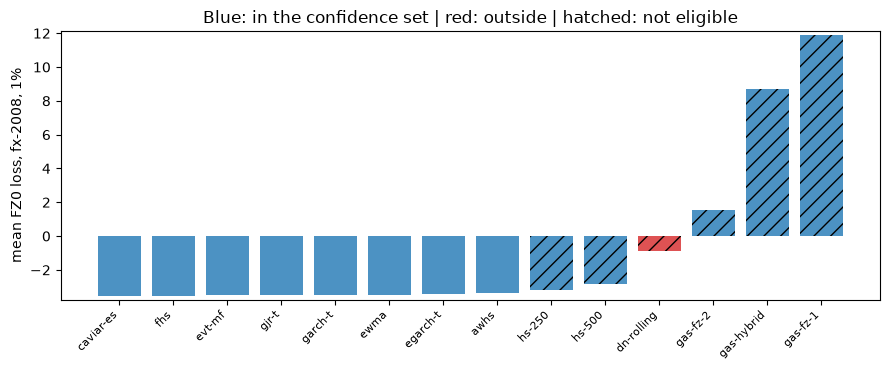

In [8]:
# Rank the models with an ES in fx-2008 at 1% by mean FZ0, coloured by the confidence set and hatched when ineligible
alpha = 0.01
book = forecasts_of("fx-2008", alpha)
inside = {m["model_id"]: m["in_set"] for m in [c for c in docs["fx-2008"]["outputs"]["comparison"]["mcs"] if c["alpha"] == alpha][0]["members"]}
ranked = sorted((fz0_loss(returns, v, e, alpha).mean(), m) for m, (v, e, level, eligible) in book.items() if e is not None)
fig, ax = plt.subplots(figsize=(9, 3.8))
for position, (score, model_id) in enumerate(ranked):
    ax.bar(position, score, color="tab:blue" if inside[model_id] else "tab:red", hatch="" if book[model_id][3] else "//", alpha=0.8)
ax.set_xticks(range(len(ranked)))
ax.set_xticklabels([m for s, m in ranked], rotation=45, ha="right", fontsize=8)
ax.set_ylim(min(s for s, m in ranked) - 0.2, max(s for s, m in ranked) + 0.2)
ax.set_ylabel("mean FZ0 loss, fx-2008, 1%")
ax.set_title("Blue: in the confidence set | red: outside | hatched: not eligible")
fig.tight_layout()
plt.show()

## Results

- **FZ0, by hand and by engine.** For `ewma` at 2.5 percent in `fx-2008` the mean FZ0 is -3.706963 by hand, by the engine and in the committed row. The loss is -3.9515 on average on a day without an exceedance and +3.7209 on the 8 exceedance days: the exceedance term is what the score punishes. The mean FZ0 and mean tick loss of all 17 models at both levels return from the arrays with a largest difference of 4.9e-09.
- **Consistency, shown by scale.** Multiplying the VaR and ES of `evt-mf` by a factor $k$ gives its lowest mean FZ0 at $k = 1.00$ (-3.7162); for `ewma` at 1.05 (-3.7114 against -3.7070 unscaled); for `hs-250` at 1.40 (-3.6350 against -3.4294 unscaled). In the 2008 crisis the historical forecast would have needed numbers 40 percent larger to score best in its family, and the score says so by a gap of 0.21.
- **Diebold-Mariano reproduces.** Choosing the champion by the rule and comparing every other model with it gives the committed champions (`caviar-es` at 1 percent and `evt-mf` at 2.5 percent in `fx-2008`; `ewma` at both levels in `rates-2022`) and the 28 or 29 committed rows of each case with a largest difference of 5.0e-09 in the statistic and the p-value. In `fx-2008` no model is significantly better than the champion on either loss. In `rates-2022` at 1 percent one is: `cf-rolling`, on the tick loss (p 0.0438). It has no ES and is not eligible, so the VaR-only ranking can differ from the VaR and ES ranking.
- **The confidence set.** At 1 percent the set holds 12 of 14 models in `equity-2007-09` (outside: `dn-rolling`, `gas-fz-2`, with MCS p-values near 0.08), 14 of 14 in `equity-2020` and `rates-2022`, 13 of 14 in `fx-2008` (outside: `dn-rolling`, p 0.049) and 2 of 14 in `mixed-2023`, where only `garch-t` and `gjr-t` stay. A window with a few days or little loss separates models poorly; `mixed-2023` separates them because no model has an exceedance in 64 days, the indicator term of FZ0 vanishes, and the score is then decided by how small the forecast ES is. The sets were computed with engine 0.7.0 and the optional `arch` package; the recomputation of `rates-2022` and `fx-2008` at both levels with engine 0.8.1 returns the same sets and the same MCS p-values (largest difference 0.0e+00), and the three other windows are read, not recomputed, because their returns are withheld.
- **The champion rule on five windows.** `equity-2007-09` has no champion because no model is eligible (all 17 fail a gate), and the file says so. `equity-2020` has 4 eligible models and champions `fhs` (FZ0 -1.986) at 1 percent and `evt-mf` (-2.364) at 2.5 percent. `rates-2022` has 4 eligible and `ewma` at both levels (-3.811, -4.002). `fx-2008` has 10 eligible and `caviar-es` and `evt-mf` (-3.557, -3.716). `mixed-2023` has 17 eligible and `gjr-t` at both levels (-4.439, -4.623). The champion changes with the window, and in no window is it a simple historical simulation.

What this notebook does not show: any test of a desk-level model (notebook 06), or the dynamic semiparametric models in detail (notebook 07).

## Summary

- VaR and ES are scored together because the pair is jointly elicitable; the FZ0 loss is the parameter-free member of that class. Its level means nothing, its differences between models do.
- A consistent score rewards the right forecast: scaling a forecast shows how far each model is from its own best scale, and a model that was too small in a crisis prefers a larger factor.
- Diebold-Mariano turns a difference in mean loss into a test; a negative sign means the first model is better. With a champion fixed, every other model is compared with it on FZ0 and on tick loss, and the committed rows come back from the arrays.
- The model confidence set answers a different question, which models cannot be told apart from the best. It is seeded, so the two windows that commit their returns recompute to the committed p-values; the three others are read, since their returns are withheld.
- The champion is chosen in two steps: eligibility by the traditional backtests, then the lowest FZ0 among the eligible models with an ES on every day. A window can have no champion, and the document says so.

**What to try next.** Pick another window pair and level in step 3 and find a model that is significantly worse than the champion on FZ0 and indistinguishable on tick loss; then continue with notebook 06, which moves from models to desks.

## References

- Gneiting, T. (2011), Making and evaluating point forecasts, Journal of the American Statistical Association 106(494). https://doi.org/10.1198/jasa.2011.r10138
- Fissler, T. and Ziegel, J. F. (2016), Higher order elicitability and Osband's principle, Annals of Statistics 44(4). https://doi.org/10.1214/16-AOS1439
- Patton, A. J., Ziegel, J. F. and Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2). https://doi.org/10.1016/j.jeconom.2018.10.008
- Diebold, F. X. and Mariano, R. S. (1995), Comparing predictive accuracy, Journal of Business and Economic Statistics 13(3). https://doi.org/10.1080/07350015.1995.10524599
- Hansen, P. R., Lunde, A. and Nason, J. M. (2011), The model confidence set, Econometrica 79(2). https://doi.org/10.3982/ECTA5771
- Nolde, N. and Ziegel, J. F. (2017), Elicitability and backtesting: perspectives for banking regulation, Annals of Applied Statistics 11(4). https://doi.org/10.1214/17-AOAS1041